# NMP trajectories and Caudal-epiblast composition

This tutorial starts from two pretrained, 20,000-step full-data COATI models: one balanced and one unbalanced. It does not retrain the vector field or the RNA-to-ATAC FiLM map.

We first inspect the inferred trajectories in reproducible RNA and ATAC UMAPs. We then follow the same 417 observed E7.5 Caudal-epiblast cells and quantify their predicted fate composition over developmental time.

In [1]:
from pathlib import Path
import sys

project_dir = next((p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "pyproject.toml").exists() and (p / "src/coati").is_dir()), None)
if project_dir is None:
    raise FileNotFoundError("Run this notebook from the COATI repository.")
for path in (project_dir / "src", project_dir / "examples"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import anndata as ad
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors
import umap
from umap import UMAP

from coati.downstream import plot_trajectory_embedding
from gastrulation.nmp_pretrained import (
    DATA_PATH, load_nmp_results, validate_nmp_inputs,
)
from gastrulation.nmp_umap import (
    ATAC_UMAP_PARAMETERS, COLORS, EXPECTED_UMAP_VERSION, NMP_CELLTYPES,
    RNA_UMAP_PARAMETERS, select_nmp_related,
)

%matplotlib inline
plt.rcParams.update({"font.family": "Arial", "font.size": 10})

## Load the pretrained models

The repository stores only the final vector-field weights, not optimizer states, logs, or intermediate checkpoints. The compact AnnData contains RNA PCA50, ATAC LSI14, time, barcode, and cell-type annotations. Checksums verify the data, FiLM map, and both model files before inference.

In [2]:
cells = ad.read_h5ad(DATA_PATH)
checks = validate_nmp_inputs()
results, manifest = load_nmp_results(cells, device="cpu")

pd.DataFrame([
    {
        "model": name,
        "iterations": result.metadata["checkpoint_iteration"],
        "C_y": result.metadata["cy"],
        "unbalanced": result.metadata["config"]["unbalancedModel"],
        "data and map verified": all(checks.values()),
    }
    for name, result in results.items()
])

,model,iterations,C_y,unbalanced,data and map verified
0,balanced,20000,0.5,False,True
1,unbalanced,20000,0.5,True,True


## RNA and ATAC trajectories in NMP UMAPs

The UMAP reducers are fitted from the stored PCA50 and LSI14 representations with fixed parameters. No reducer file is required. Exact coordinate reproduction uses `umap-learn==0.5.9.post2`. Both models start from the same observed E7.5 NMP-related cells. The fitted vector field evolves RNA states, and the frozen FiLM map projects the same paths into ATAC space.

In [3]:
if umap.__version__ != EXPECTED_UMAP_VERSION:
    raise RuntimeError(
        f"Expected umap-learn {EXPECTED_UMAP_VERSION}, found {umap.__version__}."
    )

nmp_mask, nmp_labels = select_nmp_related(cells)
rna_reference = np.asarray(cells.obsm["X_pca"][nmp_mask], dtype=np.float32)
atac_reference = np.asarray(cells.obsm["X_atac"][nmp_mask], dtype=np.float32)
rna_reducer = UMAP(**RNA_UMAP_PARAMETERS).fit(rna_reference)
atac_reducer = UMAP(**ATAC_UMAP_PARAMETERS).fit(atac_reference)

observed_time = cells.obs["time"].to_numpy(dtype=float)
initial_mask = nmp_mask & np.isclose(observed_time, 0.0)
initial = np.asarray(cells.obsm["X_pca"][initial_mask], dtype=np.float32)
trajectory_times = np.linspace(0.0, 2.5, 26)
predictions = {}
for name, result in results.items():
    prediction = result.predict_trajectory(initial, times=trajectory_times, raw=True)
    prediction["secondary"] = result.project_secondary(prediction, raw=True)
    predictions[name] = prediction

print(f"Reference cells: {nmp_mask.sum():,}")
print(f"Shared E7.5 starting cells: {initial_mask.sum():,}")

Reference cells: 7,931
Shared E7.5 starting cells: 1,035


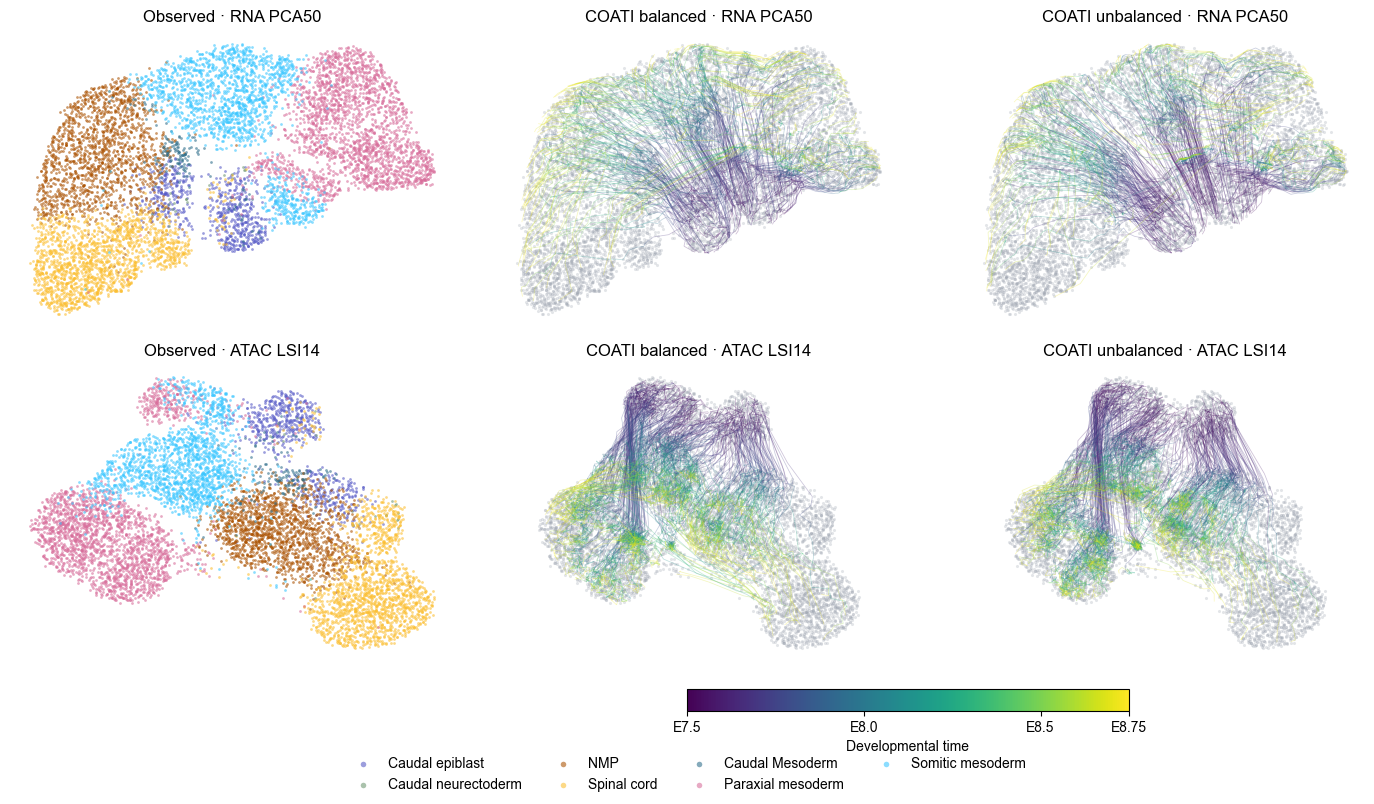

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14.5, 8.2))
references = {
    "RNA PCA50": (rna_reducer.embedding_, rna_reducer, "primary"),
    "ATAC LSI14": (atac_reducer.embedding_, atac_reducer, "secondary"),
}
for row, (modality, (reference_umap, reducer, key)) in enumerate(references.items()):
    for celltype in NMP_CELLTYPES:
        selected = nmp_labels == celltype
        axes[row, 0].scatter(
            reference_umap[selected, 0], reference_umap[selected, 1],
            s=4, color=COLORS[celltype], alpha=0.58, linewidths=0,
            rasterized=True, label=celltype,
        )
    axes[row, 0].set_title(f"Observed · {modality}")
    for column, model_name in enumerate(("balanced", "unbalanced"), start=1):
        plot_trajectory_embedding(
            predictions[model_name][key],
            reference_embedding=reference_umap,
            transform=reducer,
            times=trajectory_times,
            ax=axes[row, column],
            max_paths=300,
            random_state=17,
            show_time_colorbar=False,
            show_endpoints=False,
            linewidth=0.55,
            path_alpha=0.28,
            title=f"COATI {model_name} · {modality}",
        )
    for ax in axes[row]:
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel("")
        ax.set_ylabel("")
        for spine in ax.spines.values():
            spine.set_visible(False)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False, markerscale=2)
time_map = ScalarMappable(norm=Normalize(trajectory_times[0], trajectory_times[-1]), cmap="viridis")
colorbar = fig.colorbar(time_map, ax=axes[:, 1:].ravel().tolist(), orientation="horizontal", fraction=0.035, pad=0.09)
colorbar.set_label("Developmental time")
colorbar.set_ticks([0.0, 1.0, 2.0, 2.5], labels=["E7.5", "E8.0", "E8.5", "E8.75"])
fig.subplots_adjust(left=0.03, right=0.98, top=0.94, bottom=0.17, wspace=0.05, hspace=0.12)
plt.show()

## Composition of the Caudal-epiblast cohort

We now restrict the starting population to the 417 observed E7.5 Caudal-epiblast cells. At each of the 26 trajectory times, every predicted RNA state receives the hard 1-nearest-neighbor label from all 35,503 reference cells pooled across the four observed stages. Fine cell types are merged into five groups. Balanced composition counts particles uniformly; unbalanced composition uses the predicted native mass normalized within this cohort at every time.

In [5]:
FATE_GROUPS = (
    "Caudal epiblast", "NMP", "Posterior neural-spinal",
    "Paraxial-somitic", "Other",
)
FATE_COLORS = {
    "Caudal epiblast": "#009E73",
    "NMP": "#CC79A7",
    "Posterior neural-spinal": "#0072B2",
    "Paraxial-somitic": "#D55E00",
    "Other": "#000000",
}

def fate_group(celltype):
    if celltype in {"Caudal epiblast", "NMP"}:
        return celltype
    if celltype in {"Caudal neurectoderm", "Spinal cord", "Neural crest"}:
        return "Posterior neural-spinal"
    if celltype in {"Paraxial mesoderm", "Somitic mesoderm", "Caudal Mesoderm"}:
        return "Paraxial-somitic"
    return "Other"

def normalized_mass(log_mass):
    values = np.asarray(log_mass, dtype=float).reshape(-1)
    values = np.where(np.isfinite(values), values, np.nanmin(values))
    weights = np.exp(np.clip(values - np.max(values), -50.0, 0.0))
    return weights / weights.sum()

In [6]:
celltypes = cells.obs["celltype"].astype("string").fillna("Unknown").astype(str).to_numpy()
source_mask = np.isclose(observed_time, 0.0) & (celltypes == "Caudal epiblast")
source = np.asarray(cells.obsm["X_pca"][source_mask], dtype=np.float32)
if len(source) != 417:
    raise ValueError(f"Expected 417 source cells, found {len(source)}.")

reference = np.asarray(cells.obsm["X_pca"], dtype=np.float32)
reference_groups = np.asarray([fate_group(value) for value in celltypes])
neighbors = NearestNeighbors(n_neighbors=1, algorithm="brute", n_jobs=-1).fit(reference)
records = []
for model_name, result in results.items():
    prediction = result.predict_trajectory(source, times=trajectory_times, raw=True)
    trajectory = prediction["primary"]
    indices = neighbors.kneighbors(
        trajectory.reshape(-1, trajectory.shape[-1]), return_distance=False
    )[:, 0].reshape(trajectory.shape[:2])
    assigned = reference_groups[indices]
    for step, time in enumerate(trajectory_times):
        weights = (
            np.full(len(source), 1.0 / len(source))
            if model_name == "balanced"
            else normalized_mass(prediction["log_weights"][step])
        )
        for group in FATE_GROUPS:
            fraction = weights[assigned[step] == group].sum()
            records.append({
                "model": model_name, "step": step, "time": time,
                "fate_group": group, "percent": 100.0 * fraction,
            })

composition = pd.DataFrame(records)
terminal = composition[composition["step"] == 25].pivot(
    index="model", columns="fate_group", values="percent"
).reindex(columns=FATE_GROUPS)
terminal.round(2)

fate_group,Caudal epiblast,NMP,Posterior neural-spinal,Paraxial-somitic,Other
model,,,,,
balanced,0.0,61.15,15.11,10.55,13.19
unbalanced,0.0,55.38,18.13,8.28,18.21


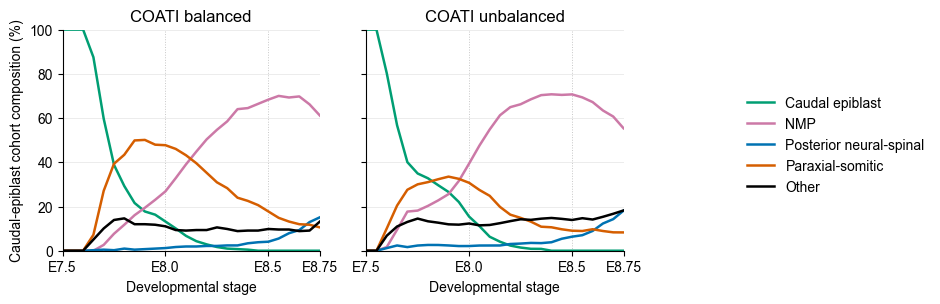

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.3), sharex=True, sharey=True)
for ax, model_name in zip(axes, ("balanced", "unbalanced")):
    local = composition[composition["model"] == model_name]
    for group in FATE_GROUPS:
        curve = local[local["fate_group"] == group].sort_values("step")
        ax.plot(curve["step"], curve["percent"], color=FATE_COLORS[group], lw=1.8, label=group)
    for step in (10, 20, 25):
        ax.axvline(step, color="#C7C7C7", lw=0.7, ls=":", zorder=0)
    ax.set_title(f"COATI {model_name}")
    ax.set_xlim(0, 25)
    ax.set_ylim(0, 100)
    ax.set_xticks([0, 10, 20, 25], ["E7.5", "E8.0", "E8.5", "E8.75"])
    ax.set_xlabel("Developmental stage")
    ax.grid(axis="y", color="#ECECEC", lw=0.7)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Caudal-epiblast cohort composition (%)")
handles, labels = axes[-1].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc="center left", bbox_to_anchor=(0.89, 0.52))
fig.subplots_adjust(left=0.10, right=0.76, bottom=0.20, top=0.87, wspace=0.18)
plt.show()